# 09marey: the Madrid to Barcelona day as a Marey diagram

**What it does:** turns the 89 trains of Wednesday 25 November 2026 (from `08mareyfeeds`: Renfe, Iryo, Ouigo) into a Marey diagram: time across, distance along the line down, one line per train. Steep lines are fast, flat steps are stops, lines that cross are one train overtaking another. Also works out the key numbers for the page and the case study, including the same line before the 2026 speed restrictions (Renfe's timetable for Wed 14 Jan 2026, the 2025 era).

- **Distance down the side:** kilometre points of the Madrid to Barcelona high-speed line (Madrid Atocha 0 to Barcelona Sants 620.9 km), from the line diagram on Wikipedia ("Madrid-Barcelona high-speed rail line", route diagram template) and the Lleida Pirineus station page (km 442.1), read 20 Nov 2026. Agreed with Likren 20 Nov (instead of straight-line distance).
- **Before the restrictions:** only Renfe is in the archived January 2026 feed, so the "before" numbers are Renfe only and are used for speeds and fastest times, not for train counts.

**Inputs:** `data/clean/marey_trips.csv` (from `08mareyfeeds`), `data/raw/renfe/2025-12-18/` (from `00renfegtfs`).
**Outputs:** `data/clean/marey_stats.csv`, `figures/09marey.png` (draft figure), `docs/data/marey.json` (for the page).

**Data credit:** Renfe Viajeros open data; Ouigo Espana via the Punto de Acceso Nacional; Iryo community feed by Clement Desouche (CC BY 4.0, clementdesouche.fr/gtfs; unofficial, timetables from iryo.eu); archives: Mobility Database. Kilometre points: Wikipedia.

## 0. Settings

In [1]:
from pathlib import Path
import datetime
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLEAN_DIR = Path("data") / "clean"
FIG_DIR = Path("figures")
PAGE_DIR = Path("docs") / "data"
BEFORE_FOLDER = Path("data") / "raw" / "renfe" / "2025-12-18"  # <- archived Renfe feed (2025 era)
DAY = "2026-11-25"  # <- the day shown
BEFORE_DAY = "2026-01-14"  # <- the 2025-era day (before the speed restrictions of Feb 2026)
BEFORE_MADRID_IDS = ["60000", "17000"]  # <- Renfe stop codes: Madrid Puerta de Atocha, Chamartin (names are spelled differently in the old feed)
BEFORE_SANTS_IDS = ["71801"]  # <- Renfe stop code: Barcelona Sants
KM = {  # <- kilometre points on the high-speed line (Wikipedia route diagram; Lleida from its station page)
    "Madrid Atocha": 0.0,
    "Guadalajara": 64.4,
    "Calatayud": 221.1,
    "Zaragoza": 306.7,
    "Lleida": 442.1,
    "Tarragona": 520.9,
    "Barcelona Sants": 620.9,
}
OPERATORS = ["Renfe", "Iryo", "Ouigo"]  # <- fixed order (colour slots 1, 2, 3)
COLOURS_LIGHT = {"Renfe": "#2a78d6", "Iryo": "#eb6834", "Ouigo": "#1baf7a"}  # <- VISUAL: figure on white (validated categorical slots 1 to 3)
COLOURS_DARK = {"Renfe": "#3987e5", "Iryo": "#d95926", "Ouigo": "#199e70"}  # <- VISUAL: page on the dark panel #1b1f26 (validated, all pairs)
SPEED_WARN = 320  # <- warn if a train would need more than this km/h between two stations
TEXT_COLOUR = "#333333"  # <- VISUAL: figure text
GRID_COLOUR = "#e4e4e4"  # <- VISUAL: station lines

FIG_DIR.mkdir(exist_ok=True)
PAGE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Trains and kilometre points

In [2]:
calls = pd.read_csv(CLEAN_DIR / "marey_trips.csv", dtype={"train": str, "stop_id": str})
missing = sorted(set(calls["station"]) - set(KM))
print(f"{calls['trip_id'].nunique()} trains, {len(calls)} station calls; stations without a km point: {missing if missing else 'none'}")
calls["km"] = calls["station"].map(KM)
calls = calls.sort_values(["trip_id", "seq"]).reset_index(drop=True)

# Checks: distance moves the right way along every train, and no train is faster than the line allows
bad_order = []
speeds = []
for trip_id, t in calls.groupby("trip_id", sort=False):
    step = np.diff(t["km"].values)
    sign = 1 if t["direction"].iat[0] == "to Barcelona" else -1
    if not (sign * step > 0).all():
        bad_order.append(trip_id)
    run = t["arr_min"].values[1:] - t["dep_min"].values[:-1]
    for a, b, km, minutes in zip(t["station"].values[:-1], t["station"].values[1:], np.abs(step), run):
        speeds.append({"trip_id": trip_id, "operator": t["operator"].iat[0], "train": t["train"].iat[0], "from": a, "to": b, "km": km, "minutes": minutes, "kmh": km / minutes * 60})
speeds = pd.DataFrame(speeds)
print(f"trains whose stations are out of order: {bad_order if bad_order else 'none'}")
print(f"average speed between stops: median {speeds['kmh'].median():.0f} km/h, max {speeds['kmh'].max():.0f} km/h")
fast = speeds[speeds["kmh"] > SPEED_WARN]
print(f"legs above {SPEED_WARN} km/h: {len(fast)}")
if len(fast):
    print(fast.round(1).to_string(index=False))

89 trains, 300 station calls; stations without a km point: none
trains whose stations are out of order: none
average speed between stops: median 190 km/h, max 222 km/h
legs above 320 km/h: 0


## 2. Before the restrictions: Renfe on Wednesday 14 January 2026

Same rules as `08mareyfeeds` (services running that day, trips calling at a Madrid station and Barcelona Sants), on the archived feed of 18 Dec 2025.

In [3]:
def read_gtfs(folder, name):
    table = pd.read_csv(Path(folder) / name, dtype=str, keep_default_na=False, encoding="utf-8-sig", skipinitialspace=True)
    table.columns = [c.strip() for c in table.columns]
    for column in table.columns:
        table[column] = table[column].str.strip()
    return table


def minutes(text):
    h, m, s = (int(x) for x in text.split(":"))
    return h * 60 + m + s / 60


with zipfile.ZipFile(BEFORE_FOLDER / "google_transit.zip") as z:
    z.extractall(BEFORE_FOLDER)
day = datetime.date.fromisoformat(BEFORE_DAY)
code_ = day.strftime("%Y%m%d")
weekday = day.strftime("%A").lower()
calendar = read_gtfs(BEFORE_FOLDER, "calendar.txt")
running = set(calendar.loc[(calendar["start_date"] <= code_) & (calendar["end_date"] >= code_) & (calendar[weekday] == "1"), "service_id"])
dates = read_gtfs(BEFORE_FOLDER, "calendar_dates.txt")
dates = dates[dates["date"] == code_]
running = (running | set(dates.loc[dates["exception_type"] == "1", "service_id"])) - set(dates.loc[dates["exception_type"] == "2", "service_id"])
stops = read_gtfs(BEFORE_FOLDER, "stops.txt")
name = dict(zip(stops["stop_id"], stops["stop_name"]))
madrid = set(BEFORE_MADRID_IDS)
sants = set(BEFORE_SANTS_IDS)
print("stations used:", [name.get(s, "?") for s in sorted(madrid | sants)])
trips = read_gtfs(BEFORE_FOLDER, "trips.txt")
trips = trips[trips["service_id"].isin(running)]
times = read_gtfs(BEFORE_FOLDER, "stop_times.txt")
times = times[times["trip_id"].isin(set(trips["trip_id"]))].copy()
times["seq"] = times["stop_sequence"].astype(int)
number = dict(zip(trips["trip_id"], trips["trip_short_name"]))
before = []
for trip_id, t in times.sort_values(["trip_id", "seq"]).groupby("trip_id", sort=False):
    ids = list(t["stop_id"])
    m = [i for i, s in enumerate(ids) if s in madrid]
    b = [i for i, s in enumerate(ids) if s in sants]
    if not m or not b:
        continue
    first, last, direction = (m[0], b[0], "to Barcelona") if m[0] < b[0] else (b[0], m[-1], "to Madrid")
    part = t.iloc[first:last + 1]
    before.append({"train": number[trip_id], "direction": direction, "dep": minutes(part["departure_time"].iat[0]), "arr": minutes(part["arrival_time"].iat[-1]), "calls": len(part) - 2})
before = pd.DataFrame(before).drop_duplicates(["train", "direction", "dep"])
before["minutes"] = before["arr"] - before["dep"]
print(f"Renfe, {weekday.title()} {BEFORE_DAY}: {len(before)} trains ({(before['direction'] == 'to Barcelona').sum()} to Barcelona, {(before['direction'] == 'to Madrid').sum()} to Madrid)")
print(f"fastest {before['minutes'].min():.0f} min, nonstop trains {(before['calls'] == 0).sum()}, median {before['minutes'].median():.0f} min")

stations used: ['Madrid-Chamartín-Clara Campoamor', 'Madrid Pta.Atocha - Almudena Grandes', 'Barcelona-Sants']
Renfe, Wednesday 2026-01-14: 46 trains (24 to Barcelona, 22 to Madrid)
fastest 157 min, nonstop trains 11, median 173 min


## 3. Key numbers

In [4]:
def clock(m):
    m = int(round(m))
    return f"{m // 60}:{m % 60:02d}"


trains = calls.groupby("trip_id").agg(operator=("operator", "first"), train=("train", "first"), direction=("direction", "first"),
                                      dep=("dep_min", "first"), arr=("arr_min", "last"), calls=("seq", "max"))
trains["calls"] = trains["calls"] - 1
trains["minutes"] = trains["arr"] - trains["dep"]
stats = []
def add(key, value, note=""):
    stats.append({"key": key, "value": value, "note": note})
    print(f"{key:34s} {value!s:>8}  {note}")

add("trains_total", len(trains), f"Wed {DAY}, both directions")
for op in OPERATORS:
    add(f"trains_{op.lower()}", int((trains["operator"] == op).sum()))
add("share_new_operators", round(float((trains["operator"] != "Renfe").mean()), 3), "Iryo + Ouigo")
add("nonstop_trains", int((trains["calls"] == 0).sum()))
add("fastest_min", float(trains["minutes"].min()), clock(trains["minutes"].min()))
add("median_min", float(trains["minutes"].median()), clock(trains["minutes"].median()))
add("slowest_min", float(trains["minutes"].max()), clock(trains["minutes"].max()))
add("fastest_min_before", float(before["minutes"].min()), f"Renfe, {BEFORE_DAY}, {clock(before['minutes'].min())}")
add("median_min_before_renfe", float(before["minutes"].median()), f"Renfe only, {BEFORE_DAY}")
add("median_min_renfe", float(trains.loc[trains["operator"] == "Renfe", "minutes"].median()), f"Renfe only, {DAY}")
line = KM["Barcelona Sants"]
add("nonstop_kmh", round(line / trains["minutes"].min() * 60), "average speed of the fastest train")
add("nonstop_kmh_before", round(line / before["minutes"].min() * 60))
for direction in ["to Barcelona", "to Madrid"]:
    d = trains[trains["direction"] == direction].sort_values("dep")
    hours = (d["dep"] // 60).value_counts()
    add(f"busiest_hour_{direction.split()[-1].lower()}", f"{int(hours.idxmax())}:00", f"{int(hours.max())} departures")
    gaps = np.diff(d["dep"].values)
    add(f"shortest_gap_{direction.split()[-1].lower()}", float(gaps.min()), "minutes between two departures")
    # overtakes: a train that leaves later but arrives earlier
    over = [(a.train, b.train) for a in d.itertuples() for b in d.itertuples() if b.dep > a.dep and b.arr < a.arr]
    add(f"overtakes_{direction.split()[-1].lower()}", len(over), "later departure, earlier arrival")
stats = pd.DataFrame(stats)
stats.to_csv(CLEAN_DIR / "marey_stats.csv", index=False)
print("saved marey_stats.csv")
print()
print(trains.groupby(["operator"]).agg(trains=("train", "size"), nonstop=("calls", lambda c: int((c == 0).sum())), median_min=("minutes", "median")).loc[OPERATORS].to_string())

trains_total                             89  Wed 2026-11-25, both directions
trains_renfe                             51  
trains_iryo                              28  
trains_ouigo                             10  
share_new_operators                   0.427  Iryo + Ouigo
nonstop_trains                           32  
fastest_min                           182.0  3:02
median_min                            197.0  3:17
slowest_min                           230.0  3:50
fastest_min_before                    157.0  Renfe, 2026-01-14, 2:37
median_min_before_renfe               173.0  Renfe only, 2026-01-14
median_min_renfe                      197.0  Renfe only, 2026-11-25
nonstop_kmh                             205  average speed of the fastest train
nonstop_kmh_before                      237  
busiest_hour_barcelona                 6:00  5 departures
shortest_gap_barcelona                  4.0  minutes between two departures
overtakes_barcelona                       9  later departure, earl

## 4. Draft figure

Madrid at the top, Barcelona at the bottom; trains to Barcelona run down to the right, trains to Madrid up to the right.

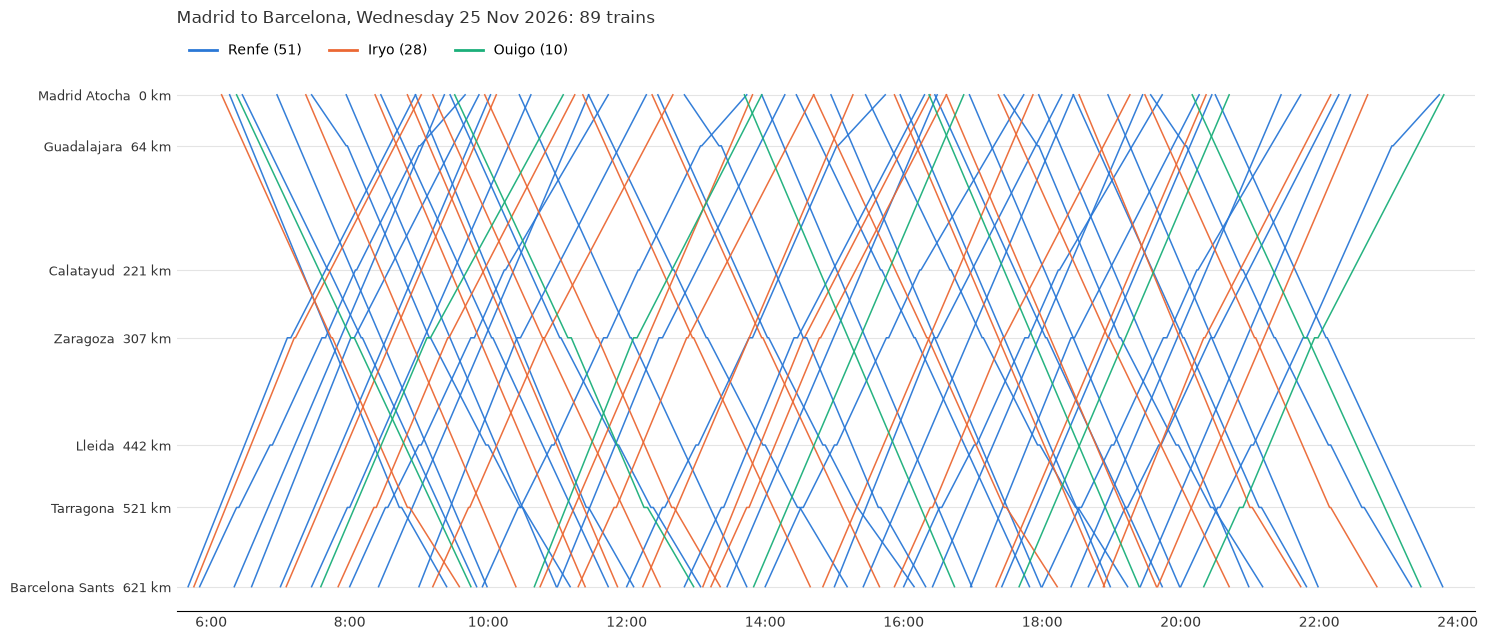

In [5]:
fig, ax = plt.subplots(figsize=(15, 6.5))
for km_value in KM.values():
    ax.axhline(km_value, color=GRID_COLOUR, linewidth=0.8, zorder=0)
for trip_id, t in calls.groupby("trip_id", sort=False):
    xs, ys = [], []
    for c in t.itertuples():
        xs += [c.arr_min / 60, c.dep_min / 60]
        ys += [c.km, c.km]
    ax.plot(xs[1:-1], ys[1:-1], color=COLOURS_LIGHT[t["operator"].iat[0]], linewidth=1.1, alpha=0.95)
ax.set_yticks(list(KM.values()))
ax.set_yticklabels([f"{k}  {v:.0f} km" for k, v in KM.items()], color=TEXT_COLOUR, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(5.5, 24.25)
ax.set_xticks(range(6, 25, 2))
ax.set_xticklabels([f"{h}:00" for h in range(6, 25, 2)], color=TEXT_COLOUR)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
handles = [plt.Line2D([], [], color=COLOURS_LIGHT[o], linewidth=2, label=f"{o} ({int((trains['operator'] == o).sum())})") for o in OPERATORS]
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=10)
ax.set_title(f"Madrid to Barcelona, Wednesday {datetime.date.fromisoformat(DAY):%d %b %Y}: {len(trains)} trains", loc="left", color=TEXT_COLOUR, fontsize=12, pad=34)
fig.tight_layout()
fig.savefig(FIG_DIR / "09marey.png", dpi=150)
plt.show()

## 5. Page data

In [6]:
out = {
    "day": DAY,
    "before_day": BEFORE_DAY,
    "stations": [{"name": k, "km": v} for k, v in KM.items()],
    "operators": OPERATORS,
    "colours": COLOURS_DARK,
    "trains": [],
    "stats": {r.key: r.value for r in stats.itertuples()},
    "credits": "Timetables: Renfe open data; Ouigo Espana via the Punto de Acceso Nacional (nap.transportes.gob.es); Iryo: unofficial community feed by Clement Desouche (CC BY 4.0, clementdesouche.fr/gtfs), timetables from iryo.eu, checked against ticket listings. Archived copies: Mobility Database. Kilometre points: Wikipedia.",
}
for trip_id, t in calls.groupby("trip_id", sort=False):
    out["trains"].append({
        "op": t["operator"].iat[0], "no": t["train"].iat[0].replace("TGV ", ""), "dir": "B" if t["direction"].iat[0] == "to Barcelona" else "M",
        "stops": [[c.km, round(c.arr_min, 1), round(c.dep_min, 1)] for c in t.itertuples()],
    })
out["trains"].sort(key=lambda r: (r["dir"], r["stops"][0][2]))
text = json.dumps(out, ensure_ascii=False, separators=(",", ":"))
(PAGE_DIR / "marey.json").write_text(text, encoding="utf-8")
print(f"saved docs/data/marey.json ({len(text) / 1024:.0f} KB, {len(out['trains'])} trains)")

saved docs/data/marey.json (11 KB, 89 trains)


___
**END**